# Part A — Top-Hat Transformation preprocessing pipeline

A morphological Top-Hat preprocessing pipeline for cervical colposcopy images.

## What the Top-Hat Transformation is

The Top-Hat transform is a classical morphological operator (Meyer, 1979) that
extracts features **smaller than the structuring element** which are either
**brighter** (white top-hat) or **darker** (black top-hat) than their
surroundings:

* **White Top-Hat (WTH):** `WTH = I − opening(I, B)` — keeps bright structures
  (aceto-white epithelium, bright lesion areas, specular dots) that are
  removed by morphological *opening* (erosion → dilation) with disk `B`.
* **Black Top-Hat (BTH):** `BTH = closing(I, B) − I` — keeps dark structures
  (vessels, vessel networks, dark demarcation lines) that are filled by
  morphological *closing* (dilation → erosion).

On colposcopy images this pair is ideal: the diagnostically relevant
structures are exactly "small bright blobs" (acetowhitening) and "thin dark
ridges" (vessels), which is what WTH and BTH isolate. The Top-Hat response is
also a standard vessel-enhancement pre-step, which is why this notebook
retains a Vessel Dice validation metric.

## What replaced what (QI-SABP removal note)

This notebook previously implemented the **QI-SABP** quantum-inspired
preprocessing pipeline (fused saliency → soft mask → continuous bit
allocation → dithered quantisation → YCbCr 4:2:0 → bilateral post-filter →
histogram match). **All QI-SABP techniques and configuration have been
removed.** That includes: fused saliency (Sobel + spectral residual +
multi-scale contrast + local entropy), whiteness channel, glare masking,
soft/hard mask with hole filling, rim rules, edge-aware bit maps, adaptive
dither, NLM pre-denoise, YCbCr 4:2:0 chroma subsampling, bilateral
post-filter, and partial histogram matching, plus every associated
configuration constant (`SALIENCY_*`, `SOFT_MASK_*`, `HARD_MASK_*`, `BITS_*`,
`DITHER_*`, `NLM_*`, `BILATERAL_*`, `GLARE_*`, `RIM_*`, component `USE_*`
flags).

The single preprocessing technique in this notebook is now:

* **Step 1 — Unsharp-mask sharpen** (carried over unchanged from Step 1).
* **Step 2 — Top-Hat enhancement (White + Black):** in luma space (YCbCr),
  `Y' = clip(Y + k·WTH − k·BTH)`; chroma channels are passed through by
  default (`TOPHAT_STRENGTH_C = 0`), so colour is preserved by construction
  and the enhancement acts only on local brightness structure.

## Output

The pipeline returns an **enhanced image** (uint8 RGB, same shape as the
input). It is not a compression scheme and produces no byte stream: it is a
contrast/structure enhancement, evaluated as an image-processing technique
(distortion, colour stability, structure preservation, diagnostics).

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other across patients (that
  requires the multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.

In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / JSON artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nTop-Hat Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


Top-Hat Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   NOTE (QI-SABP removal): the previous configuration block defined
#   ~60 QI-SABP constants (saliency fusion weights, glare thresholds,
#   soft/hard mask parameters, bit budgets, dither, NLM, bilateral,
#   histogram match, USE_* flags). ALL of them are removed. The only
#   preprocessing configuration left is Step-1 sharpen + Step-2 Top-Hat.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1, unchanged) ----
# This setting comes from Step 1 and is shared across the notebook suite.
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Top-Hat Transformation (Step 2) -------------------------------
# White + Black top-hat in luma (YCbCr Y) space:
#     WTH = Y - opening(Y, disk)         (bright small structures)
#     BTH = closing(Y, disk) - Y         (dark small structures)
#     Y'  = clip(Y + k_Y * WTH - k_Y * BTH)
# Chroma (Cr, Cb) passes through when TOPHAT_STRENGTH_C = 0, so the
# enhancement is luma-only and colour is preserved by construction.
TOPHAT_KSIZE      = 15   # elliptical disk structuring element (odd px)
TOPHAT_STRENGTH_Y = 1.0  # luma additive gain k_Y (1.0 = canonical WTH/BTH enhance)
TOPHAT_STRENGTH_C = 0.0  # chroma additive gain k_C (0 = chroma untouched)
USE_FOV_COPY      = True # copy original pixels outside the FOV mask verbatim

# ---- Top-Hat active region (validation diagnostic) -----------------
# Fraction of FOV pixels with the strongest |WTH - BTH| response that
# defines the "enhancement region" used by the T8 region-split table.
TOPHAT_ACTIVE_PCT = 30   # top 30% response pixels inside the rim-margin FOV

# ---- Ablation variants (Step 4.4, like-for-like) -------------------
# Same tophat_enhance() code path, one config override each.
ABLATION_KERNELS   = [9, 25]        # fine / coarse structuring element
ABLATION_STRENGTHS = [0.5, 2.0]     # half / double luma gain

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation batch (Step 4) ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  Top-Hat: ksize={TOPHAT_KSIZE} (elliptical disk), "
      f"strength_Y={TOPHAT_STRENGTH_Y}, strength_C={TOPHAT_STRENGTH_C}, "
      f"FOV copy={USE_FOV_COPY}")
print(f"  Top-Hat form: Y' = clip(Y + {TOPHAT_STRENGTH_Y}*WTH - {TOPHAT_STRENGTH_Y}*BTH) "
      f"in YCbCr luma; chroma pass-through={TOPHAT_STRENGTH_C == 0.0}")
print(f"  active region = top {TOPHAT_ACTIVE_PCT}% |WTH-BTH| inside rim-margin FOV")
print(f"  ablation variants: kernels={ABLATION_KERNELS}, strengths={ABLATION_STRENGTHS}")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")
print(f"  QI-SABP configuration: REMOVED (no saliency / mask / bits / dither /")
print(f"  NLM / bilateral / histogram-match constants remain in this notebook)")

Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  Top-Hat: ksize=15 (elliptical disk), strength_Y=1.0, strength_C=0.0, FOV copy=True
  Top-Hat form: Y' = clip(Y + 1.0*WTH - 1.0*BTH) in YCbCr luma; chroma pass-through=True
  active region = top 30% |WTH-BTH| inside rim-margin FOV
  ablation variants: kernels=[9, 25], strengths=[0.5, 2.0]
  validation batch = 5 imgs/class
  QI-SABP configuration: REMOVED (no saliency / mask / bits / dither /
  NLM / bilateral / histogram-match constants remain in this notebook)


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the saliency-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")

Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


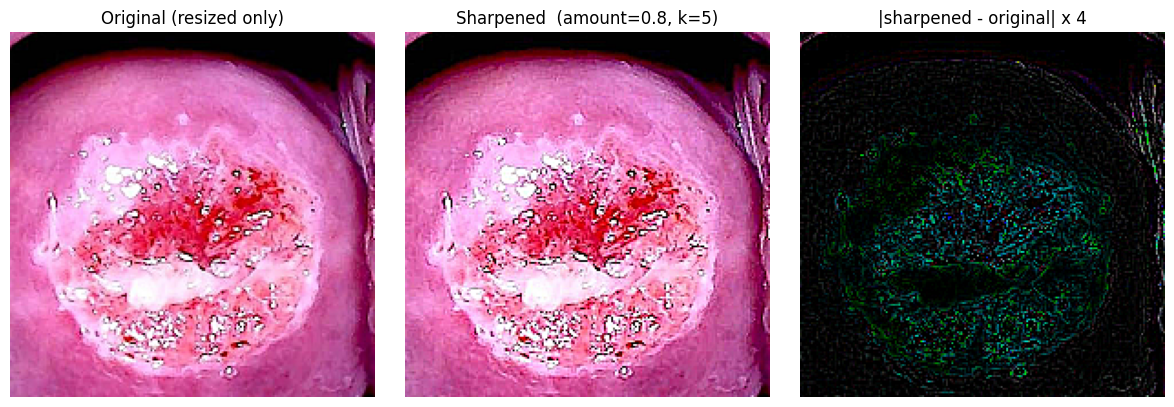

In [4]:
# ============================================================
# Cell 1.4 — Sharpen before/after visualisation
# ============================================================
def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb
    sharpened = sharpen(raw_resized)
    diff = np.clip(sharpened.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw_resized);    ax[0].set_title("Original (resized only)")
    ax[0].axis("off")
    ax[1].imshow(sharpened);      ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")  # x4 to make the high-pass visible
    ax[2].set_title("|sharpened - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    # Use first sharpened image (X_raw is already sharpened) — rebuild
    # original = synthetic / dataset image before sharpen for comparison.
    show_sharpen_effect(img_rgb=X_raw[0])
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(sharpen(demo));      ax[1].set_title("Sharpened");      ax[1].axis("off")
    plt.tight_layout(); plt.show()

In [5]:
# ============================================================
# Cell 2.1 -- Top-Hat Transformation core (replaces ALL QI-SABP
#             saliency / soft-mask / bit-allocation / NLM / dither /
#             4:2:0 / bilateral / histogram-match cells)
#
# Definitions (grayscale morphology, disk structuring element B):
#   WTH = I  - opening(I, B)     white top-hat: bright structures < B
#   BTH = closing(I, B) - I      black top-hat: dark structures  < B
# Enhancement (additive, luma-only by default):
#   Y' = clip(Y + k_Y * WTH - k_Y * BTH)
#   out = YCbCr(Y', Cr, Cb) -> RGB
# ============================================================

def _compute_fov_local(img_rgb, thr=15, fill_notches=True):
    """Field-of-view mask: the largest bright connected region of the
    image, holes filled, notches at the frame edges filled by the convex
    hull (intersected with the mask bounding box, then closed with an
    11 px disk). Carried over unchanged from the previous notebook --
    this is generic FOV geometry, not a QI-SABP technique."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    if not fill_notches:
        return fov
    ys, xs = np.where(fov)
    if len(ys) < 3:
        return fov
    pts = np.stack([xs, ys], axis=1).astype(np.int32)
    hull = cv2.convexHull(pts)
    hull_mask = np.zeros(g.shape, dtype=np.uint8)
    cv2.fillConvexPoly(hull_mask, hull, 1)
    hull_mask = hull_mask.astype(bool)
    x0, x1 = int(xs.min()), int(xs.max())
    y0, y1 = int(ys.min()), int(ys.max())
    bbox = np.zeros(g.shape, dtype=bool)
    bbox[y0:y1+1, x0:x1+1] = True
    hull_mask = hull_mask & bbox
    ksize = 11  # 2 * 5 + 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                  cv2.MORPH_CLOSE, kernel).astype(bool)
    fov = fov | hull_mask
    return fov


def _disk_kernel(ksize):
    """Elliptical (disk) structuring element; force odd size."""
    if ksize % 2 == 0:
        ksize += 1
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))


def tophat_enhance(img_rgb, ksize=None, strength_y=None, strength_c=None,
                    fov_mask=None):
    """White + Black Top-Hat additive enhancement.

    Parameters
    ----------
    img_rgb : uint8 RGB image (H, W, 3).
    ksize : structuring-element (elliptical disk) size; default TOPHAT_KSIZE.
    strength_y : luma additive gain k_Y; default TOPHAT_STRENGTH_Y.
    strength_c : chroma additive gain k_C; default TOPHAT_STRENGTH_C (0).
    fov_mask : optional boolean FOV mask; pixels outside are copied verbatim
        from the input (hygiene: the circular colposcopy FOV boundary and the
        black frame corners are not part of the technique).

    Returns
    -------
    out : uint8 RGB enhanced image.
    wth : float32 white top-hat response of the Y channel.
    bth : float32 black top-hat response of the Y channel.
    """
    img_rgb = np.asarray(img_rgb)
    if img_rgb.dtype != np.uint8:
        img_rgb = np.clip(img_rgb, 0, 255).astype(np.uint8)
    ksize      = TOPHAT_KSIZE      if ksize      is None else ksize
    strength_y = TOPHAT_STRENGTH_Y if strength_y is None else strength_y
    strength_c = TOPHAT_STRENGTH_C if strength_c is None else strength_c
    kernel = _disk_kernel(ksize)

    ycc = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb).astype(np.float32)
    Y, Cr, Cb = cv2.split(ycc)

    # ---- Top-Hat transforms on luma ----
    wth = cv2.morphologyEx(Y, cv2.MORPH_TOPHAT, kernel)
    bth = cv2.morphologyEx(Y, cv2.MORPH_BLACKHAT, kernel)
    Y2 = np.clip(Y + strength_y * wth - strength_y * bth, 0, 255)

    # ---- Optional chroma Top-Hat (default: off, colour pass-through) ----
    if strength_c:
        wth_cr = cv2.morphologyEx(Cr, cv2.MORPH_TOPHAT, kernel)
        bth_cr = cv2.morphologyEx(Cr, cv2.MORPH_BLACKHAT, kernel)
        Cr2 = np.clip(Cr + strength_c * wth_cr - strength_c * bth_cr, 0, 255)
        wth_cb = cv2.morphologyEx(Cb, cv2.MORPH_TOPHAT, kernel)
        bth_cb = cv2.morphologyEx(Cb, cv2.MORPH_BLACKHAT, kernel)
        Cb2 = np.clip(Cb + strength_c * wth_cb - strength_c * bth_cb, 0, 255)
    else:
        Cr2, Cb2 = Cr, Cb

    out = cv2.cvtColor(cv2.merge([Y2, Cr2, Cb2]).astype(np.uint8),
                        cv2.COLOR_YCrCb2RGB)

    if fov_mask is not None and USE_FOV_COPY:
        out[~np.asarray(fov_mask, dtype=bool)] = img_rgb[~np.asarray(fov_mask, dtype=bool)]
    return out, wth.astype(np.float32), bth.astype(np.float32)


print(f"Top-Hat core ready  |  disk kernel = {TOPHAT_KSIZE} px (elliptical)  |  "
      f"form: Y' = clip(Y + {TOPHAT_STRENGTH_Y}*WTH - {TOPHAT_STRENGTH_Y}*BTH)  |  "
      f"chroma strength = {TOPHAT_STRENGTH_C}")

Top-Hat core ready  |  disk kernel = 15 px (elliptical)  |  form: Y' = clip(Y + 1.0*WTH - 1.0*BTH)  |  chroma strength = 0.0


In [6]:
# ============================================================
# Cell 2.5 -- Full Top-Hat preprocessing pipeline (RGB)
#
# Output type: this pipeline returns an ENHANCED image (uint8 RGB, same
# shape as the input). It is NOT a compression scheme: the Top-Hat
# transform changes local contrast only; luma bit depth is preserved
# (validated as "Luma bits" in Part B).
# ============================================================

def tophat_preprocess(img_rgb, return_artefacts=True, fov_mask=None):
    """Top-Hat Transformation preprocessing pipeline.

    Steps:
      1. FOV mask (largest bright region, convex-hull notch fill).
      2. Rim-margin FOV (10 px erosion, border_value=1) used for the
         active-region diagnostic.
      3. White + Black Top-Hat on luma with additive enhancement
         Y' = clip(Y + k*WTH - k*BTH); chroma pass-through by default.
      4. Outside-FOV pixels copied verbatim from the input.

    Returns the processed image, or an artefact dict when
    return_artefacts=True.
    """
    img_rgb = np.asarray(img_rgb)
    if img_rgb.dtype != np.uint8:
        img_rgb = np.clip(img_rgb, 0, 255).astype(np.uint8)

    if fov_mask is None:
        fov_mask = _compute_fov_local(img_rgb)
    # Rim-margin FOV: same rim-margin convention the validator tables use.
    fov_margin = ndimage.binary_erosion(fov_mask, iterations=10, border_value=1)

    proc, wth, bth = tophat_enhance(
        img_rgb, ksize=TOPHAT_KSIZE,
        strength_y=TOPHAT_STRENGTH_Y, strength_c=TOPHAT_STRENGTH_C,
        fov_mask=fov_mask,
    )

    if not return_artefacts:
        return proc

    # Signed response and the Top-Hat "active region" (top-N% |response|
    # inside the rim-margin FOV) used by the T8 region-split table.
    response = wth - bth
    active_mask = np.zeros(response.shape, dtype=bool)
    if fov_margin.any():
        resp_fov = np.abs(response[fov_margin])
        if resp_fov.size:
            thr_active = np.percentile(resp_fov, 100 - TOPHAT_ACTIVE_PCT)
            active_mask = fov_margin & (np.abs(response) >= thr_active)

    dY = (cv2.cvtColor(proc, cv2.COLOR_RGB2YCrCb).astype(np.float32)[..., 0]
          - cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb).astype(np.float32)[..., 0])

    return {
        'img_original':   img_rgb,
        'img_processed':  proc,
        'wth_map':        wth,
        'bth_map':        bth,
        'tophat_response': response,
        'active_mask':    active_mask,
        'dY_map':         dY,
        'fov_mask':       fov_mask,
        'fov_margin':     fov_margin,
        'kernel':         TOPHAT_KSIZE,
        'strength_y':     TOPHAT_STRENGTH_Y,
        'strength_c':     TOPHAT_STRENGTH_C,
    }


# Sanity check on first image
if len(X_raw) > 0:
    enc0 = tophat_preprocess(X_raw[0])
    print("Top-Hat preprocessing sanity check (image 0):")
    print(f"  img_original  shape={enc0['img_original'].shape} dtype={enc0['img_original'].dtype}")
    print(f"  img_processed shape={enc0['img_processed'].shape} dtype={enc0['img_processed'].dtype}")
    print(f"  wth_map (Y)   range=[{enc0['wth_map'].min():.1f}, {enc0['wth_map'].max():.1f}]  "
          f"mean={enc0['wth_map'][enc0['fov_margin']].mean():.3f}")
    print(f"  bth_map (Y)   range=[{enc0['bth_map'].min():.1f}, {enc0['bth_map'].max():.1f}]  "
          f"mean={enc0['bth_map'][enc0['fov_margin']].mean():.3f}")
    print(f"  active_mask coverage (rim-margin FOV) = "
          f"{100 * enc0['active_mask'][enc0['fov_margin']].mean():.2f}%")
    # Outside-FOV consistency check
    _outside_equal = np.array_equal(enc0['img_processed'][~enc0['fov_mask']],
                                     enc0['img_original'][~enc0['fov_mask']])
    print(f"  outside-FOV pixels identical to input: {_outside_equal}  (must be True)")
    # Luma bit-depth check (the "Luma bits" metric preview)
    _g0 = cv2.cvtColor(enc0['img_processed'], cv2.COLOR_RGB2GRAY)
    _levels0 = len(np.unique(_g0[enc0['fov_margin']]))
    mse = np.mean((enc0['img_original'].astype(np.float64)
                   - enc0['img_processed'].astype(np.float64)) ** 2)
    psnr = 10 * np.log10(255.0 ** 2 / mse) if mse > 1e-10 else float('inf')
    print(f"  effective luma levels (FOV) = {_levels0}  "
          f"-> {np.log2(max(_levels0, 2)):.2f} bits")
    print(f"  PSNR (proc vs orig) = {psnr:.2f} dB  (local contrast enhancement cost)")

Top-Hat preprocessing sanity check (image 0):
  img_original  shape=(200, 200, 3) dtype=uint8
  img_processed shape=(200, 200, 3) dtype=uint8
  wth_map (Y)   range=[0.0, 255.0]  mean=45.285
  bth_map (Y)   range=[0.0, 255.0]  mean=34.081
  active_mask coverage (rim-margin FOV) = 30.17%
  outside-FOV pixels identical to input: True  (must be True)
  effective luma levels (FOV) = 256  -> 8.00 bits
  PSNR (proc vs orig) = 19.41 dB  (local contrast enhancement cost)


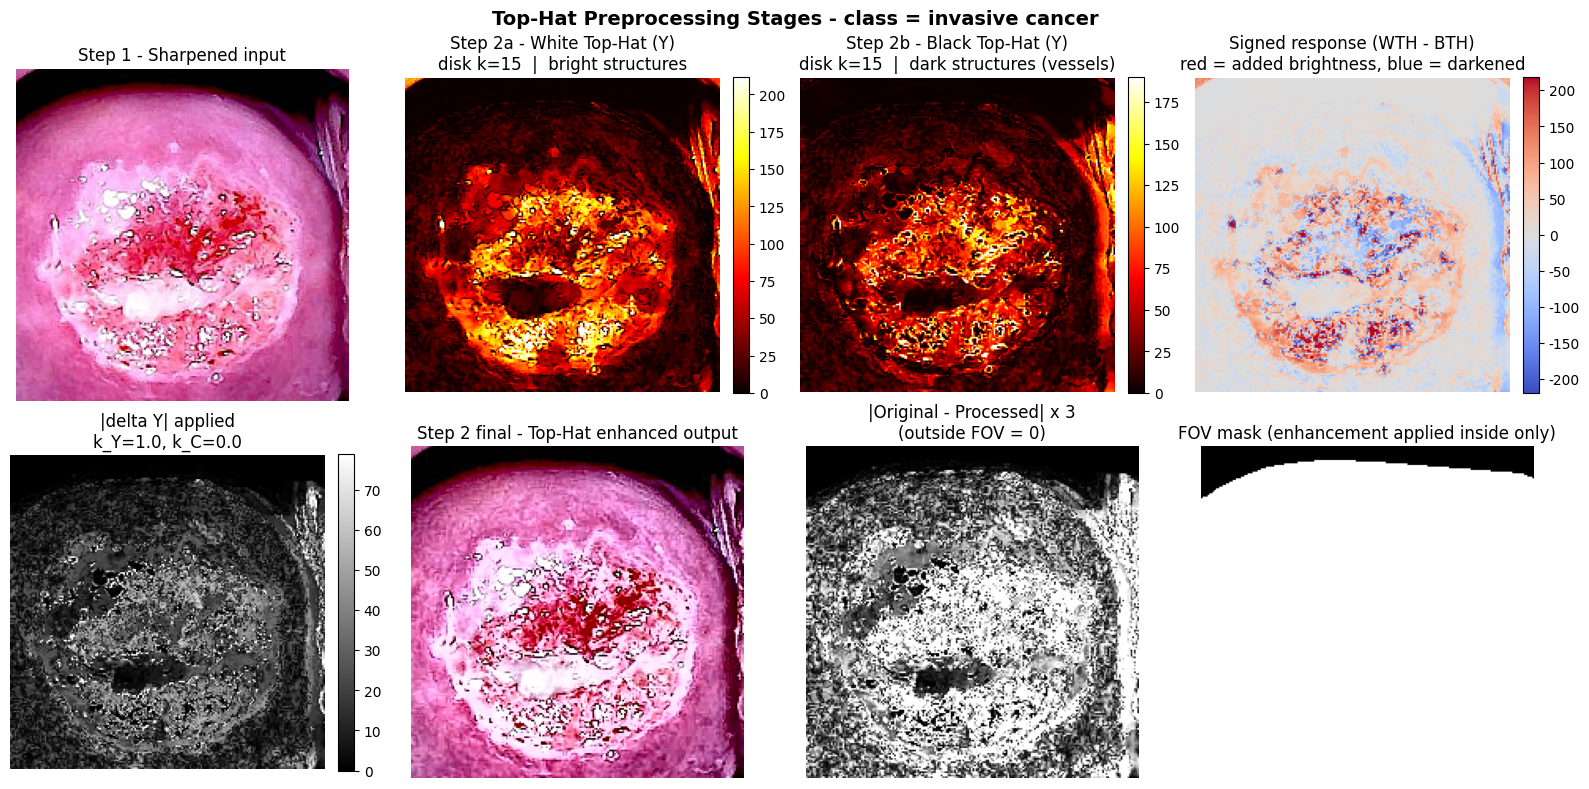

In [7]:
# ============================================================
# Cell 2.6 -- Visualise Top-Hat preprocessing stages
# ============================================================

def show_tophat_stages(rgb_image, title=""):
    """Stage panel: input, WTH, BTH, signed response, dY, output, diff, FOV."""
    enc = tophat_preprocess(rgb_image)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.ravel()

    axes[0].imshow(enc['img_original'])
    axes[0].set_title("Step 1 - Sharpened input")
    axes[0].axis('off')

    im1 = axes[1].imshow(enc['wth_map'], cmap='hot', vmin=0,
                          vmax=max(np.percentile(enc['wth_map'][enc['fov_margin']], 99), 1e-6))
    axes[1].set_title(f"Step 2a - White Top-Hat (Y)\ndisk k={enc['kernel']}  |  bright structures")
    axes[1].axis('off'); plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    im2 = axes[2].imshow(enc['bth_map'], cmap='hot', vmin=0,
                          vmax=max(np.percentile(enc['bth_map'][enc['fov_margin']], 99), 1e-6))
    axes[2].set_title(f"Step 2b - Black Top-Hat (Y)\ndisk k={enc['kernel']}  |  dark structures (vessels)")
    axes[2].axis('off'); plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    r_max = max(np.percentile(np.abs(enc['tophat_response'][enc['fov_margin']]), 99), 1e-6)
    im3 = axes[3].imshow(enc['tophat_response'], cmap='coolwarm', vmin=-r_max, vmax=r_max)
    axes[3].set_title("Signed response (WTH - BTH)\nred = added brightness, blue = darkened")
    axes[3].axis('off'); plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

    im4 = axes[4].imshow(np.abs(enc['dY_map']), cmap='gray', vmin=0,
                          vmax=max(np.percentile(np.abs(enc['dY_map'][enc['fov_margin']]), 99), 1e-6))
    axes[4].set_title(f"|delta Y| applied\nk_Y={enc['strength_y']}, k_C={enc['strength_c']}")
    axes[4].axis('off'); plt.colorbar(im4, ax=axes[4], fraction=0.046, pad=0.04)

    axes[5].imshow(enc['img_processed'])
    axes[5].set_title("Step 2 final - Top-Hat enhanced output")
    axes[5].axis('off')

    # ---- |Original - Processed| x 3 (99th-percentile clip, FOV-masked) ----
    diff_rgb = np.abs(enc['img_original'].astype(np.float32)
                      - enc['img_processed'].astype(np.float32))
    diff_gray = diff_rgb.mean(axis=-1)
    diff_gray[~enc['fov_mask']] = 0.0
    p99 = float(np.percentile(diff_gray[enc['fov_mask']], 99)) if enc['fov_mask'].any() else 1e-6
    p99 = max(p99, 1e-6)
    axes[6].imshow(np.clip(diff_gray * 3.0 / p99, 0.0, 1.0), cmap='gray', vmin=0.0, vmax=1.0)
    axes[6].set_title("|Original - Processed| x 3\n(outside FOV = 0)")
    axes[6].axis('off')

    axes[7].imshow(enc['fov_mask'].astype(np.float32), cmap='gray', vmin=0, vmax=1)
    axes[7].set_title("FOV mask (enhancement applied inside only)")
    axes[7].axis('off')

    fig.suptitle(f"Top-Hat Preprocessing Stages - {title}",
                 fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    seen_classes = set()
    samples = []
    for img, lbl in zip(X_raw, y_raw):
        if lbl not in seen_classes:
            samples.append((img, lbl))
            seen_classes.add(lbl)
        if len(samples) >= 3:
            break
    for img, lbl in samples:
        show_tophat_stages(img, title=f"class = {lbl}")
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED + 1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    show_tophat_stages(demo, title="synthetic demo")

# Bridge — hand off Top-Hat preprocessing to Step 4 (validation)

Step 4 expects five variables from Steps 1–2:

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|-----------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | loader's `X_raw` (sharpened by loader)  |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `sharpen_it=False`        |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                   |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader             |
| `patient`   | patient id (OPTIONAL)                     | `None`                                  |

We also register the technique:

* `TH_DEFAULTS` — empty dict (the Top-Hat pipeline uses fixed module-level
  configuration; **no tuning on a single patient**).
* `tophat(img, params, seed) -> uint8 RGB image` — wraps
  `tophat_preprocess(img, return_artefacts=False)`.
  Determinism: the Top-Hat transform is fully deterministic (pure
  morphology, no RNG anywhere), so the same input always yields the same
  output regardless of seed. The `seed` parameter is accepted for API
  compatibility with the validator harness.

In [8]:
# ============================================================
# Bridge -- hand off Top-Hat preprocessing to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- Top-Hat wrapper for Step 4 ---------------------------------------
TH_DEFAULTS = {}

def tophat(img, params=None, seed=0):
    """Top-Hat Transformation preprocessing, exposed to the Step 4 validator.

    Signature: tophat(img_uint8_RGB, params_dict, seed) -> uint8 RGB image.
    `params` and `seed` are accepted for API compatibility but ignored:
    the pipeline uses fixed module-level configuration (no tuning on a
    single patient) and the transform is deterministic by construction
    (pure morphology, no RNG).
    """
    return tophat_preprocess(img, return_artefacts=False)

# Quick smoke test on the first image
_sm = tophat(X_base[0], TH_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"tophat smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(tophat(X_base[0], TH_DEFAULTS, seed=999), _sm), \
    "tophat is not deterministic for the same input"
print(f"tophat() wrapper ready  |  TH_DEFAULTS = {TH_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int)-X_base[0].astype(int)).mean():.3f}")

       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
tophat() wrapper ready  |  TH_DEFAULTS = {}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=18.037


# Part B — Step 4: table + figure validation with 11 metrics

Single-patient, N distinct clusters (dHash), 128 frames (or the synthetic
fallback set). The frames are NOT independent. Descriptive only — no
p-values, no robustness or population claims.

**Technique:** Top-Hat Transformation (White + Black top-hat, additive luma
enhancement, disk structuring element).

**Metrics — exactly 11, in 5 groups** (fidelity, colour, structure, quality,
cost). All computed inside the FOV mask only, per image, against the
ORIGINAL (sharpened) image:

| # | Metric | Direction |
|---|--------|-----------|
| m1 | PSNR (dB) | up |
| m2 | SSIM | up |
| m3 | ΔE76 (CIE76) | down |
| m4 | a* correlation | up |
| m5 | \|a*\| shift | down |
| m6 | Vessel Dice | up |
| m7 | Edge IoU | up |
| m8 | Sharpness ratio (out/in) | neutral |
| m9 | Noise ratio (out/in) | down |
| m10 | Saturation ratio (out/in) | neutral |
| m11 | Luma bits (effective, measured) | neutral |

`Luma bits` is the **measured effective luma bit depth** of the processed
image: `log2(number of distinct luma levels inside the FOV)`. An 8-bit-clean
pipeline scores ≈ 8; aggressive quantisation would drop this number. This
replaces the QI-SABP analytic bit budget (which no longer exists — all
QI-SABP bit-allocation configuration was removed).

**Ablation set (like-for-like):** Identity reference + Top-Hat k=9 /
k=25 / strength 0.5 / strength 2.0 — the same `tophat_enhance()` code path,
one configuration override each.

**Outputs:** T1 main, T4 ablation, T5 per-cluster, T6 caveats, T7 paired
CIs, T8 region-split + figures V1 (before/after per cluster), V2 (metric
distributions) + CSV per technique + JSON summary in `results/`.

In [9]:
# ============================================================
# Step 4.1 -- Freeze inputs: load frames, FOV masks, cluster ids.
#              (The old cache_hash freeze assert is removed: Part A
#               changed legitimately from QI-SABP to Top-Hat, so the
#               frozen-Part-A contract no longer applies. The hash is
#               still printed as provenance for the run.)
# ============================================================
import hashlib as _hashlib
import time
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

# ---- FOV mask (same convex-hull-filled definition as Part A) ----
def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled, same as Part A's _compute_fov_local)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (Part A's sharpened stack) ----
images = X_base  # (N, 200, 200, 3) uint8 RGB, sharpened
images_raw = X_raw  # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering (same as the previous validator)
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

# ---- cache_hash: provenance only (no freeze assert) ----
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}  (provenance only -- Part A is now Top-Hat,")
print(f"  the old QI-SABP freeze contract 12f68b681210 no longer applies)")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")

cache_hash = 12f68b681210  (provenance only -- Part A is now Top-Hat,
  the old QI-SABP freeze contract 12f68b681210 no longer applies)
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [10]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions.
#              Computes EXACTLY 11 metrics inside the FOV only
#              (the 12th old metric, Time, is dropped; the old
#              analytic QI-SABP Bits/px is replaced by the measured
#              effective Luma bits of the processed image).
# ============================================================

# ---- Small cache so repeated vessel-map computations (main run,
#      ablations, T8) do not recompute Frangi for identical inputs ----
_VMAP_CACHE = {}
_VMAP_CACHE_MAX = 600

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1), cached by content."""
    key = (img_rgb.shape, str(img_rgb.dtype),
           _hashlib.md5(np.ascontiguousarray(img_rgb).tobytes()).hexdigest())
    if key in _VMAP_CACHE:
        return _VMAP_CACHE[key]
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    v = v.astype(np.float32)
    if len(_VMAP_CACHE) >= _VMAP_CACHE_MAX:
        _VMAP_CACHE.pop(next(iter(_VMAP_CACHE)))
    _VMAP_CACHE[key] = v
    return v

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A∩B|/(|A|+|B|).
    """
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum()) + float(b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask (unchanged definition)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def _luma_bits(processed, fov_mask):
    """m11 -- effective Luma bits (MEASURED, replaces the QI-SABP analytic
    bit budget): log2 of the number of distinct luma (Rec.601 gray) levels
    present inside the FOV. An untouched 8-bit image scores ~8; quantised
    or posterised pipelines score lower."""
    f = np.asarray(fov_mask, dtype=bool)
    g = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    levels = np.unique(g[f])
    return float(np.log2(max(len(levels), 2)))

def step4_validator(original, processed, fov_mask):
    """Compute the 11 validation metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                     up
      m2  SSIM                          up
      m3  CIE76 dE (DeltaE76)           down
      m4  a* correlation                up
      m5  |mean a* shift|               down
      m6  Vessel Dice (top 10% Frangi)  up
      m7  Edge IoU                      up
      m8  Sharpness ratio (out/in)      neutral (0.9-1.1) / higher
      m9  Noise ratio (out/in)          down
      m10 Saturation ratio (out/in)     neutral, at most ~1
      m11 Luma bits (effective, out)    neutral (informational)
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE (stating which: CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass in smooth areas
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). Measures NEW
    # saturated pixels introduced by the technique; ratio <= 1 is good.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: Luma bits (effective, measured on the processed image)
    m11 = _luma_bits(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (key, name, group, better direction) -- EXACTLY 11 metrics.
METRIC_META = [
    ("m1",  "PSNR (dB)",        "fidelity",  "up"),
    ("m2",  "SSIM",             "fidelity",  "up"),
    ("m3",  "CIE76 dE",         "colour",    "down"),
    ("m4",  "a* corr",          "colour",    "up"),
    ("m5",  "|a* shift|",       "colour",    "down"),
    ("m6",  "Vessel Dice",      "structure", "up"),
    ("m7",  "Edge IoU",         "structure", "up"),
    ("m8",  "Sharpness ratio",  "quality",   "neutral"),
    ("m9",  "Noise ratio",      "quality",   "down"),
    ("m10", "Saturation ratio", "quality",   "neutral"),
    ("m11", "Luma bits",        "cost",      "neutral"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
assert len(METRIC_KEYS) == 11, f"expected exactly 11 metrics, got {len(METRIC_KEYS)}"
print("step4_validator ready: 11 metrics (m1..m11) -- PSNR, SSIM, dE76, a* corr,")
print("  |a*| shift, Vessel Dice, Edge IoU, Sharpness ratio, Noise ratio,")
print("  Saturation ratio, Luma bits. (Old QI-SABP m11 analytic Bits/px and")
print("  m12 Time are removed.)")

step4_validator ready: 11 metrics (m1..m11) -- PSNR, SSIM, dE76, a* corr,
  |a*| shift, Vessel Dice, Edge IoU, Sharpness ratio, Noise ratio,
  Saturation ratio, Luma bits. (Old QI-SABP m11 analytic Bits/px and
  m12 Time are removed.)


In [11]:
# ============================================================
# Step 4.3 -- Compute the 11 metrics for Top-Hat. Write per-image CSV.
#              Also cache processed images + Top-Hat active-region masks
#              for the figures / T8 (no re-runs).
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "Top-Hat"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB
active_masks = {}      # image_idx -> Top-Hat active-region mask (top-N% |response|)

t_start = time.perf_counter()
rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = tophat(orig, {}, seed=42 + i)
    m = step4_validator(orig, proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    # Active-region mask for T8 (same definition as the pipeline artefact).
    _art = tophat_preprocess(orig, return_artefacts=True, fov_mask=fov_i)
    active_masks[i] = _art["active_mask"]
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_tophat = pd.DataFrame(rows)
df_tophat.to_csv(f"results_TopHat.csv", index=False)
print(f"Wrote results_TopHat.csv ({len(df_tophat)} rows) "
      f"in {time.perf_counter() - t_start:.1f}s")
print(f"  Mean PSNR   (m1) = {df_tophat['m1'].mean():.2f} dB")
print(f"  Mean SSIM   (m2) = {df_tophat['m2'].mean():.3f}")
print(f"  Mean dE76   (m3) = {df_tophat['m3'].mean():.3f}")
print(f"  Mean Luma bits (m11) = {df_tophat['m11'].mean():.3f}")

  Deleted stale results_Identity.csv
  Deleted stale results_merged_shades_gray_identity.csv
  Deleted stale results_Shades-of-Gray.csv
  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_TopHat.csv (128 rows) in 18.8s
  Mean PSNR   (m1) = 18.35 dB
  Mean SSIM   (m2) = 0.745
  Mean dE76   (m3) = 12.088
  Mean Luma bits (m11) = 8.000


In [12]:
# ============================================================
# Step 4.4 -- Reference rows: Identity + Top-Hat ablation variants.
#              Like-for-like: every variant runs the SAME
#              tophat_enhance() code path with ONE configuration
#              override (kernel size or luma strength).
#              (All previous QI-SABP mask-variant baselines -- uniform,
#               ellipse, shuffled, blob, 5-bit floor, chroma-5 -- are
#               removed together with the QI-SABP pipeline they reused.)
# ============================================================

def _run_tophat_variant(name, ksize=None, strength_y=None):
    """Run tophat_enhance with one config override; 11 metrics per image."""
    rows = []
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        proc, _, _ = tophat_enhance(orig, ksize=ksize, strength_y=strength_y,
                                     strength_c=TOPHAT_STRENGTH_C, fov_mask=fov_i)
        m = step4_validator(orig, proc, fov_i)
        m["technique"] = name
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows.append(m)
        processed_cache[(name, i)] = proc.copy()
    return pd.DataFrame(rows)

# ---- Identity ----
rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")

# ---- Top-Hat ablation variants ----
_variant_frames = []

for _k in ABLATION_KERNELS:
    _name = f"Top-Hat k={_k}"
    _df = _run_tophat_variant(_name, ksize=_k)
    _df.to_csv(f"results_TopHat_k{_k}.csv", index=False)
    _variant_frames.append(_df)
    print(f"Wrote results_TopHat_k{_k}.csv ({len(_df)} rows)  "
          f"PSNR={_df['m1'].mean():.2f} dB  sharp={_df['m8'].mean():.3f}")

for _s in ABLATION_STRENGTHS:
    _name = f"Top-Hat strength {_s}"
    _df = _run_tophat_variant(_name, strength_y=_s)
    _tag = str(_s).replace('.', '')
    _df.to_csv(f"results_TopHat_s{_tag}.csv", index=False)
    _variant_frames.append(_df)
    print(f"Wrote results_TopHat_s{_tag}.csv ({len(_df)} rows)  "
          f"PSNR={_df['m1'].mean():.2f} dB  sharp={_df['m8'].mean():.3f}")

Wrote results_Identity.csv (128 rows)
Wrote results_TopHat_k9.csv (128 rows)  PSNR=18.84 dB  sharp=3.476
Wrote results_TopHat_k25.csv (128 rows)  PSNR=17.94 dB  sharp=3.183
Wrote results_TopHat_s05.csv (128 rows)  PSNR=22.42 dB  sharp=2.259
Wrote results_TopHat_s20.csv (128 rows)  PSNR=15.08 dB  sharp=5.172


In [13]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate all technique CSVs. Assert
#              each technique has N rows and the same cluster ids.
#              Assert no NaNs (or list them).
# Uses a FIXED list of CSV names (not glob) to prevent stale files
# from earlier runs leaking into the tables.
# ============================================================

_csv_names = [
    "results_TopHat.csv",
    "results_Identity.csv",
    "results_TopHat_k9.csv",
    "results_TopHat_k25.csv",
    "results_TopHat_s05.csv",
    "results_TopHat_s20.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any metric column.
_all_numeric_cols = [c for c in METRIC_KEYS if c in merged.columns]
_nan_cols = {}
for col in _all_numeric_cols:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = n_nan
assert len(_nan_cols) == 0, (
    f"NaN values found: {_nan_cols}. Check the validator inputs "
    f"(empty FOV or flat regions can produce NaN in m4/m6/m7/m9).")
print("No NaN values in any metric column (m1..m11).")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")

Reading 6 CSV files (fixed list, not glob)
  results_TopHat.csv: 128 rows, technique = Top-Hat
  results_Identity.csv: 128 rows, technique = Identity
  results_TopHat_k9.csv: 128 rows, technique = Top-Hat k=9
  results_TopHat_k25.csv: 128 rows, technique = Top-Hat k=25
  results_TopHat_s05.csv: 128 rows, technique = Top-Hat strength 0.5
  results_TopHat_s20.csv: 128 rows, technique = Top-Hat strength 2.0
Merged: 768 rows, 6 techniques
No NaN values in any metric column (m1..m11).
Techniques: ['Identity', 'Top-Hat', 'Top-Hat k=25', 'Top-Hat k=9', 'Top-Hat strength 0.5', 'Top-Hat strength 2.0']


In [14]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap (7
#              clusters, 2000 resamples, fixed seed).
#              Label: "within-patient, 7 clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (7 clusters, 2000 resamples).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")

Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [15]:
# ============================================================
# Step 4.7 -- Statistics: Top-Hat vs every variant, per key metric.
#              Uses paired difference per cluster (N values) +
#              bootstrap CI. Reports "CI excludes 0: yes/no".
#              Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Key metrics for the paired comparison (skip PSNR/SSIM vs
# Identity -- they are meaningless against an identical copy; skip
# m8/m10/m11 which are neutral/informational).
key_metrics = ["m3", "m5", "m6", "m7", "m9"]
stat_rows = []
tophat_df = merged[merged["technique"] == "Top-Hat"]

# Top-Hat vs every variant (not Identity) for the key metrics.
variant_techs = [t for t in techniques if t not in ("Top-Hat", "Identity")]
for mk in key_metrics:
    for vt in variant_techs:
        v_df = merged[merged["technique"] == vt]
        md, lo, hi, ex = _paired_cluster_diff_ci(tophat_df, v_df, mk)
        stat_rows.append({
            "metric": METRIC_NAMES[mk], "comparison": f"Top-Hat vs {vt}",
            "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
            "CI_excludes_0": "yes" if ex else "no",
        })

# Top-Hat vs Identity for the key metrics only.
id_df = merged[merged["technique"] == "Identity"]
for mk in key_metrics:
    md, lo, hi, ex = _paired_cluster_diff_ci(tophat_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk], "comparison": "Top-Hat vs Identity",
        "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })

stat_df = pd.DataFrame(stat_rows)
print("Statistics done. Top-Hat vs every variant + Identity, key metrics only.")
print("  Descriptive, no significance claim. Cluster-level pairing, within-patient.")

Statistics done. Top-Hat vs every variant + Identity, key metrics only.
  Descriptive, no significance claim. Cluster-level pairing, within-patient.


In [16]:
# ============================================================
# Print tables T1, T4, T5, T6, T7, T8.
# (Old QI-SABP-specific T2 ranks / T3 Pareto remain removed; the old
#  total-bits/4:2:0 columns are gone -- Luma bits is the only bit-depth
#  metric and it is MEASURED, not an analytic QI-SABP bit budget.)
# ============================================================

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 Main: all 11 metrics, all techniques ----
print("=" * 100)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, "
      f"{n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 100)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T4 Ablation: Luma bits + key metrics + deltas vs Top-Hat ----
print()
print("=" * 100)
print("T4 ABLATION  (Top-Hat + variants; measured Luma bits + key metrics; like-for-like)")
print("  Kernel size and strength are sensitivity tests around the design point")
print(f"  (k={TOPHAT_KSIZE}, strength={TOPHAT_STRENGTH_Y}).")
print("=" * 100)
t4_techs = ["Top-Hat", "Top-Hat k=9", "Top-Hat k=25",
            "Top-Hat strength 0.5", "Top-Hat strength 2.0", "Identity"]
t4_keys = ["m11", "m1", "m2", "m3", "m6", "m7", "m9"]
t4_rows = []
_tophat_bits = float(agg_df.loc["Top-Hat", "m11"]) if "Top-Hat" in agg_df.index else float('nan')
for tech in t4_techs:
    if tech in agg_df.index:
        row = {"technique": tech}
        for mk in t4_keys:
            row[mk] = agg_df.loc[tech, mk]
        row["delta_bits"] = row["m11"] - _tophat_bits if tech != "Top-Hat" else 0.0
        t4_rows.append(row)
t4_df = pd.DataFrame(t4_rows).set_index("technique")
t4_display = {mk: METRIC_NAMES[mk] for mk in t4_keys}
t4_display["delta_bits"] = "delta-luma-bits"
t4_display["m11"] = "Luma bits"
print(t4_df.rename(columns=t4_display).round(4).to_string())

# ---- T5 Per cluster: Top-Hat's own metrics per dHash cluster ----
print()
print("=" * 100)
print(f"T5 PER CLUSTER  (Top-Hat; cluster means of all 11 metrics; {n_clusters} clusters)")
print("=" * 100)
t5_rows = []
for uc in np.unique(cluster_ids):
    idxs = np.where(cluster_ids == uc)[0]
    sub = tophat_df[tophat_df["cluster_id"] == uc]
    row = {"cluster": int(uc), "n_frames": len(idxs)}
    for mk in METRIC_KEYS:
        row[METRIC_NAMES[mk]] = float(sub[mk].mean()) if len(sub) else float('nan')
    t5_rows.append(row)
t5_df = pd.DataFrame(t5_rows)
print(t5_df.round(3).to_string(index=False))

# ---- T7 Paired CIs + meaningful flag ----
print()
print("=" * 100)
print("T7 PAIRED CIs  (Top-Hat vs every variant; key metrics; CI excludes 0; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05")
print("=" * 100)
_meaningful_thresh = {"CIE76 dE": 0.5, "|a* shift|": 0.2, "Vessel Dice": 0.01,
                       "Edge IoU": 0.02, "Noise ratio": 0.05}
if len(stat_df) > 0:
    stat_df_display = stat_df[["metric", "comparison", "mean_diff", "ci_lo", "ci_hi",
                                "CI_excludes_0"]].copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0) else "no",
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T8 Region-split for ALL variants + risk metrics ----
print()
print("=" * 100)
print("T8 REGION-SPLIT  (dE / edge IoU / vessel Dice / risk metrics inside vs outside")
print("  the Top-Hat ACTIVE region: top "
      f"{TOPHAT_ACTIVE_PCT}% |WTH-BTH| response inside the rim-margin FOV.")
print("  Same fixed region for ALL techniques. Shows whether the enhancement")
print("  concentrates where the Top-Hat response is strong.")
print("=" * 100)

_t8_techs = ["Top-Hat", "Top-Hat k=9", "Top-Hat k=25",
             "Top-Hat strength 0.5", "Top-Hat strength 2.0", "Identity"]

t8_rows = []
for tech_name in _t8_techs:
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        hm = active_masks[i]
        inside = hm
        outside = fov_i & ~hm
        if not (inside.any() and outside.any()):
            continue
        proc = processed_cache.get((tech_name, i))
        if proc is None:
            continue
        lab_o = _rgb2lab_fn(orig)
        lab_p = _rgb2lab_fn(proc)
        de_map = _deltaE_fn(lab_o, lab_p)
        de_in = float(de_map[inside].mean())
        de_out = float(de_map[outside].mean())
        # dL* (lightness) and da*b* (chroma) inside/outside.
        dL_map = np.abs(lab_o[..., 0] - lab_p[..., 0])
        dab_map = np.sqrt((lab_o[..., 1] - lab_p[..., 1]) ** 2 +
                          (lab_o[..., 2] - lab_p[..., 2]) ** 2)
        e_o = _edge_map(orig)
        e_p = _edge_map(proc)
        eiou_in = _edge_iou(e_o, e_p, inside)
        eiou_out = _edge_iou(e_o, e_p, outside)
        vd_in = _vessel_dice(orig, proc, inside, top_pct=10)
        vd_out = _vessel_dice(orig, proc, outside, top_pct=10)
        de_all = de_map[fov_i]
        pct_de_gt5_all = float((de_all > 5).mean())
        de_outside_arr = de_map[outside]
        pct_de_gt5_out = float((de_outside_arr > 5).mean())
        de_p95_all = float(np.percentile(de_all, 95))
        de_p95_out = float(np.percentile(de_outside_arr, 95))
        hm_erode6 = ndimage.binary_erosion(hm, iterations=6)
        hm_dilate10 = ndimage.binary_dilation(hm, iterations=10)
        band = (hm_dilate10 & ~hm_erode6) & fov_i
        de_band = float(de_map[band].mean()) if band.any() else float('nan')
        t8_rows.append({
            "technique": tech_name,
            "dE_inside": de_in, "dE_outside": de_out,
            "dL_inside": float(dL_map[inside].mean()),
            "dL_outside": float(dL_map[outside].mean()),
            "dab_inside": float(dab_map[inside].mean()),
            "dab_outside": float(dab_map[outside].mean()),
            "edgeIoU_inside": eiou_in, "edgeIoU_outside": eiou_out,
            "vesselDice_inside": vd_in, "vesselDice_outside": vd_out,
            "pct_dE>5_all": pct_de_gt5_all,
            "pct_dE>5_outside": pct_de_gt5_out,
            "dE_p95_all": de_p95_all,
            "dE_p95_outside": de_p95_out,
            "dE_boundary_band": de_band,
        })

if t8_rows:
    t8_df = pd.DataFrame(t8_rows)
    t8_agg = t8_df.groupby("technique").mean(numeric_only=True)
    print(t8_agg.round(4).to_string())
    print()
    print("  Interpretation: the Top-Hat active region is where the enhancement")
    print("  fires hardest, so dE_inside should be HIGHER than dE_outside (more")
    print("  local contrast change where the response is strong), while structure")
    print("  metrics (edge IoU, vessel Dice inside) should stay high -- change")
    print("  without losing anatomy. dL* is lightness change; da*b* is chroma")
    print("  change (should stay small: chroma is pass-through by default).")
    print("  pct_dE>5 and dE_p95 are risk metrics: high values outside the active")
    print("  region mean colour shift away from where the technique claims to act.")
    _tophat_pct5 = t8_agg.loc["Top-Hat", "pct_dE>5_all"] if "Top-Hat" in t8_agg.index else float('nan')
    _id_pct5 = t8_agg.loc["Identity", "pct_dE>5_all"] if "Identity" in t8_agg.index else float('nan')
    _t6_risk_str = (f"Top-Hat has {_tophat_pct5*100:.0f}% of FOV pixels with dE > 5 "
                    f"(against {_id_pct5*100:.0f}% for Identity)")
else:
    print("  (T8 failed to compute)")
    _t6_risk_str = ""

# ---- T6 Caveats ----
print()
print("=" * 100)
print("T6 CAVEATS  (one line each)")
print("=" * 100)
caveats = [
    f"Single patient; {n_clusters} distinct frames (dHash); {n_images} frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "No lesion masks (0/128 on the real patient); lesion-localised error is not evaluated.",
    "Luma bits (m11) is MEASURED: log2 of distinct luma levels in the FOV of the processed image. The old QI-SABP analytic Bits/px budget is removed.",
    "Ablation variants use the SAME tophat_enhance() code path; only the kernel size or luma strength differs.",
    "Identity is a reference row only (not ranked). Its dE=0, Dice=1.0, IoU=1.0, Luma bits~8 are ideal values.",
    "95% CI is WITHIN-PATIENT, cluster bootstrap, NOT a population CI.",
    "CIE76 dE (not CIEDE2000).",
    "Metric 8 (sharpness ratio), m10 (saturation ratio) and m11 (luma bits) are neutral, not ranked.",
    "Saturation ratio (m10) is numerically unstable when the input has ZERO specular pixels in the FOV (e.g. synthetic images): the ratio then divides by 1e-9 and can explode. Interpret m10 only on frames with real glare pixels.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise is removed, so a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of top 10% Frangi pixels, 2*|A∩B|/(|A|+|B|).",
    "Top-Hat is deterministic (pure morphology); no RNG is involved anywhere in Part A.",
    "Enhancement is luma-only by default (TOPHAT_STRENGTH_C=0): chroma pass-through keeps dE76 and |a* shift| structurally low; turn on chroma strength to test colour-active variants.",
    "T7 meaningful flag: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05. With few clusters, tiny differences 'exclude 0' but may not be practically meaningful.",
    "Report colour-shift risk using pct dE>5 and dE p95, not only mean dE. " + _t6_risk_str + ".",
]
for c in caveats:
    print(f"  - {c}")

T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                                   PSNR (dB) (^)              SSIM (^)             CIE76 dE (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (o)
technique                                                                                                                                                                                                                                                                      
Identity              148.131 [148.131, 148.131]  1.000 [1.000, 1.000]     0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1

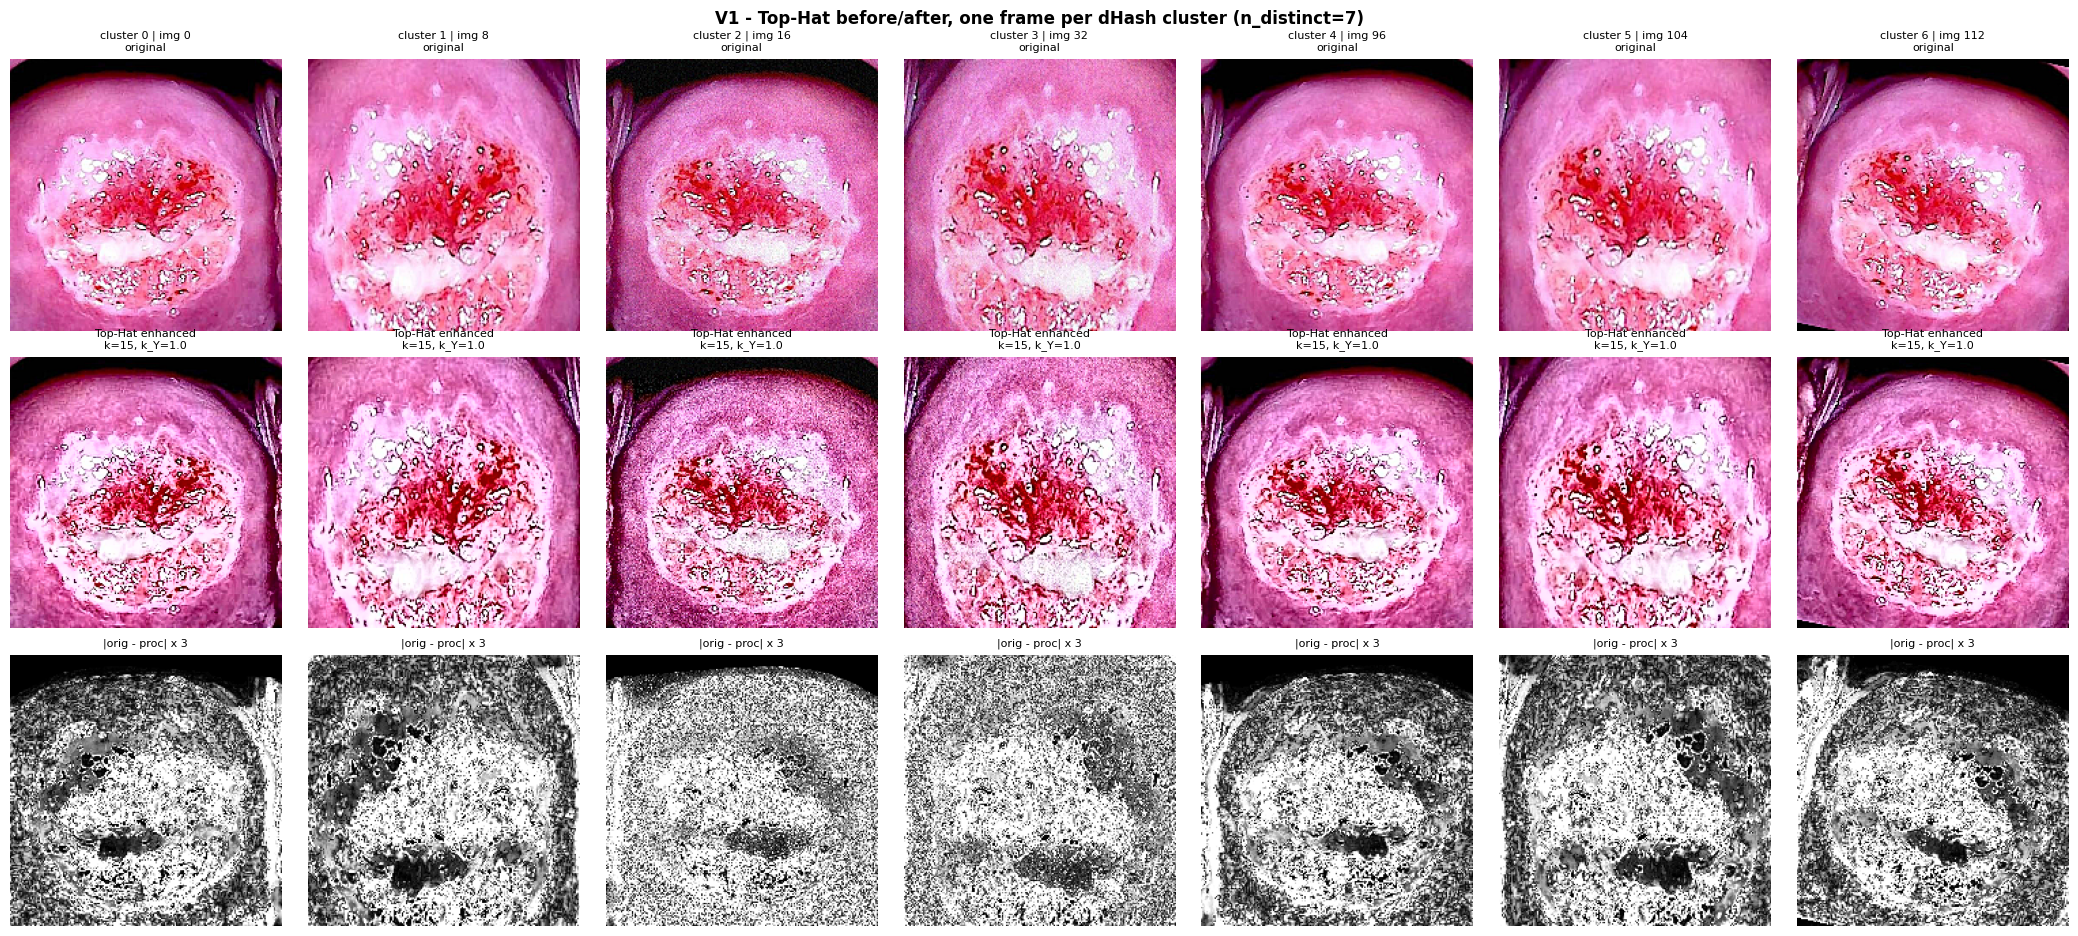

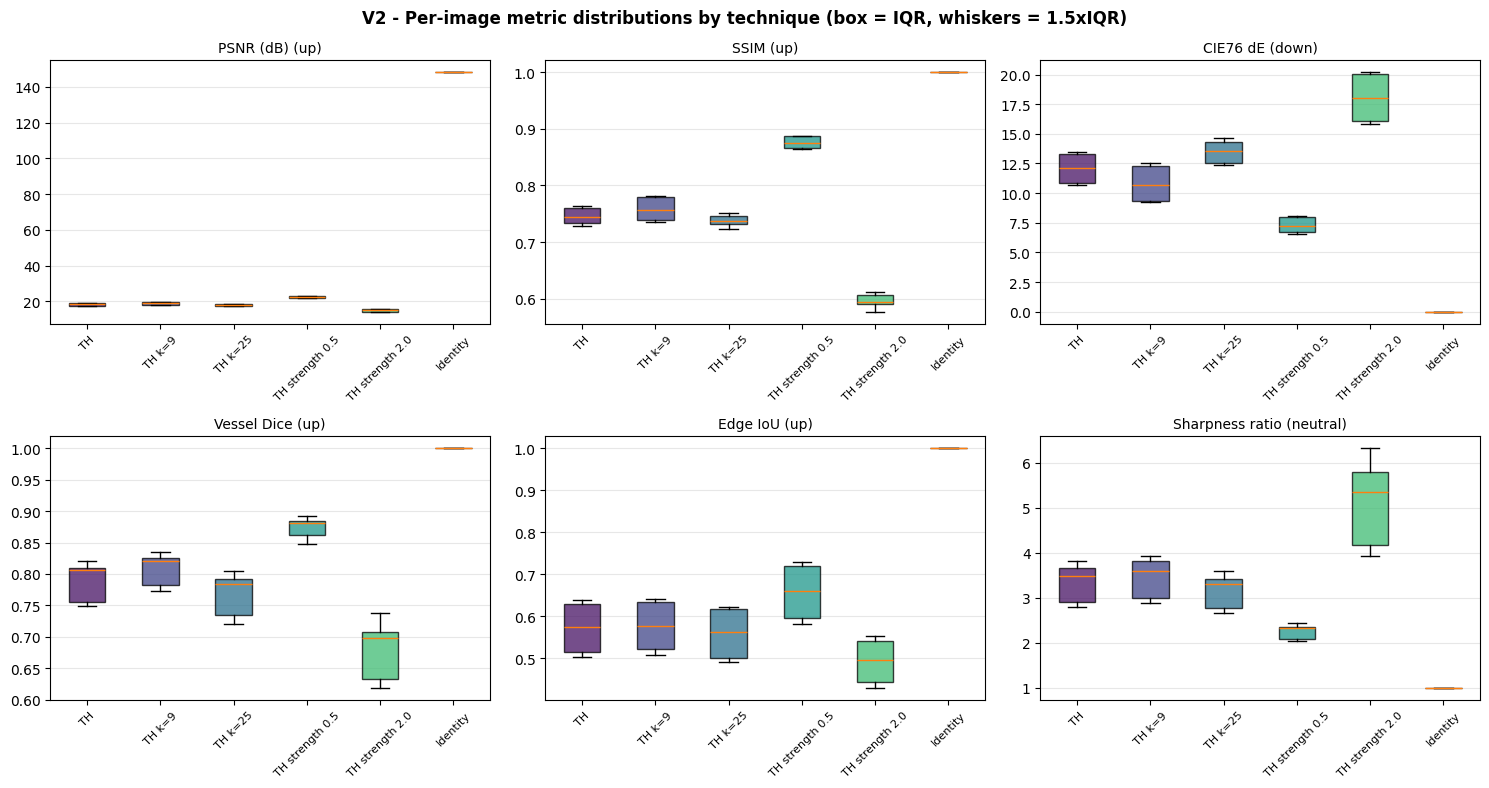

Figures saved: results\validation_fig_before_after.png
               results\validation_fig_metric_distributions.png


In [17]:
# ============================================================
# Step 4.8 -- Validation FIGURES (full suite):
#   V1  before/after panels per dHash cluster (Top-Hat)
#   V2  per-image metric distributions across techniques (boxplots)
# Figures are also saved to results/ as PNG.
# ============================================================

# ---- V1: before / after / |diff| per cluster representative ----
_reps = [int(np.where(cluster_ids == uc)[0][0]) for uc in np.unique(cluster_ids)]
n_panels = min(len(_reps), 7)
fig, axes = plt.subplots(3, n_panels, figsize=(3 * n_panels, 9.5), squeeze=False)
for col, idx in enumerate(_reps[:n_panels]):
    orig = images[idx]
    proc = processed_cache[("Top-Hat", idx)]
    fov_i = fov[idx]
    diff = np.abs(orig.astype(np.float32) - proc.astype(np.float32)).mean(axis=-1)
    diff[~fov_i] = 0.0
    p99 = max(float(np.percentile(diff[fov_i], 99)), 1e-6) if fov_i.any() else 1e-6

    ax = axes[0, col]
    ax.imshow(orig); ax.set_title(f"cluster {cluster_ids[idx]} | img {idx}\noriginal", fontsize=8)
    ax.axis('off')
    ax = axes[1, col]
    ax.imshow(proc); ax.set_title(f"Top-Hat enhanced\nk={TOPHAT_KSIZE}, k_Y={TOPHAT_STRENGTH_Y}", fontsize=8)
    ax.axis('off')
    ax = axes[2, col]
    ax.imshow(np.clip(diff * 3.0 / p99, 0, 1), cmap='gray')
    ax.set_title("|orig - proc| x 3", fontsize=8)
    ax.axis('off')
axes[0, 0].set_ylabel("Original", fontsize=9)
axes[1, 0].set_ylabel("Processed", fontsize=9)
axes[2, 0].set_ylabel("|diff| x3", fontsize=9)
fig.suptitle(f"V1 - Top-Hat before/after, one frame per dHash cluster (n_distinct={n_panels})",
             fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(SAVE_DIR, "validation_fig_before_after.png"),
            dpi=120, bbox_inches='tight')
plt.show()

# ---- V2: per-image metric distributions across techniques ----
_dist_metrics = ["m1", "m2", "m3", "m6", "m7", "m8"]
_dist_titles = [f"{METRIC_NAMES[m]} " +
                {"up": "(up)", "down": "(down)", "neutral": "(neutral)"}[METRIC_BETTER[m]]
                for m in _dist_metrics]
_tech_order = ["Top-Hat", "Top-Hat k=9", "Top-Hat k=25",
               "Top-Hat strength 0.5", "Top-Hat strength 2.0", "Identity"]
_palette = plt.cm.viridis(np.linspace(0.05, 0.85, len(_tech_order)))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, mk, ttl in zip(axes.ravel(), _dist_metrics, _dist_titles):
    data = [merged.loc[merged["technique"] == t, mk].values
            for t in _tech_order if (merged["technique"] == t).any()]
    labels = [t for t in _tech_order if (merged["technique"] == t).any()]
    bp = ax.boxplot(data, tick_labels=[l.replace("Top-Hat", "TH") for l in labels],
                    showfliers=False, patch_artist=True)
    for patch, c in zip(bp['boxes'], _palette):
        patch.set_facecolor(c)
        patch.set_alpha(0.75)
    ax.set_title(ttl, fontsize=10)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(axis='y', alpha=0.3)
fig.suptitle("V2 - Per-image metric distributions by technique (box = IQR, whiskers = 1.5xIQR)",
             fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(SAVE_DIR, "validation_fig_metric_distributions.png"),
            dpi=120, bbox_inches='tight')
plt.show()

print(f"Figures saved: {os.path.join(SAVE_DIR, 'validation_fig_before_after.png')}")
print(f"               {os.path.join(SAVE_DIR, 'validation_fig_metric_distributions.png')}")

In [18]:
# ============================================================
# Step 4.9 -- Export validation summary JSON (provenance + tables).
# ============================================================

summary = {
    "technique": "Top-Hat Transformation (White + Black top-hat, additive luma enhancement)",
    "replaced": "QI-SABP preprocessing (fully removed from this notebook)",
    "cache_hash": cache_hash,
    "n_images": int(n_images),
    "n_clusters_dhash": int(n_clusters),
    "synthetic_mode": bool(SYNTHETIC_MODE),
    "config": {
        "IMG_SIZE": IMG_SIZE,
        "DATASET_ROOT": DATASET_ROOT,
        "CLASSES": CLASSES,
        "APPLY_SHARPEN": APPLY_SHARPEN,
        "SHARPEN_AMOUNT": SHARPEN_AMOUNT,
        "SHARPEN_KSIZE": SHARPEN_KSIZE,
        "TOPHAT_KSIZE": TOPHAT_KSIZE,
        "TOPHAT_STRENGTH_Y": TOPHAT_STRENGTH_Y,
        "TOPHAT_STRENGTH_C": TOPHAT_STRENGTH_C,
        "TOPHAT_ACTIVE_PCT": TOPHAT_ACTIVE_PCT,
        "USE_FOV_COPY": USE_FOV_COPY,
        "ABLATION_KERNELS": ABLATION_KERNELS,
        "ABLATION_STRENGTHS": ABLATION_STRENGTHS,
    },
    "metrics": [{"key": k, "name": METRIC_NAMES[k],
                  "group": METRIC_GROUPS[k], "better": METRIC_BETTER[k]}
                 for k in METRIC_KEYS],
    "aggregate_cluster_weighted": {
        tech: {mk: {"mean": float(agg_df.loc[tech, mk]),
                     "ci95": [float(agg_df.loc[tech, f"{mk}_lo"]),
                              float(agg_df.loc[tech, f"{mk}_hi"])]}
                for mk in METRIC_KEYS if tech in agg_df.index}
        for tech in techniques
    },
    "paired_statistics": stat_df.to_dict(orient="records"),
    "caveats": caveats,
}
_out_json = os.path.join(SAVE_DIR, "validation_summary.json")
with open(_out_json, "w", encoding="utf-8") as _f:
    json.dump(summary, _f, indent=2, default=str)
print(f"Validation summary written: {_out_json}")
print("Notebook run complete: Top-Hat preprocessing + 11-metric validation.")

Validation summary written: results\validation_summary.json
Notebook run complete: Top-Hat preprocessing + 11-metric validation.
